# Day 2 — Overfitting, Preprocessing, Tuning & Model Comparison
**System 7 · Week 3 · Commit: `day-16-tuning-model-comparison`**

**Module A:** over/underfitting, feature scaling, encoding, `GridSearchCV`, `RandomizedSearchCV`, model-comparison task.

**Practice questions solved today:** Q6 – Q8 · **Module task:** compare multiple models and justify the best one · **Learning topic:** Bias–variance trade-off

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, time, warnings
from scipy.stats import loguniform
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, ConfusionMatrixDisplay, classification_report
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
R = {}

## Dataset — student performance (numeric + categorical columns)
To practise scaling **and** encoding I generate a reproducible student dataset (1,200 students) and save it as `students.csv`.
Target `result` is **Pass / Fail** (final score ≥ 55). It mixes numeric columns (study hours, attendance, GPA…) and categorical ones (parent education, internet, tutoring, school type).

In [2]:
def make_students(n=1200, seed=42):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "study_hours":   rng.normal(3, 1.5, n).clip(0, 10).round(1),
        "attendance":    rng.normal(80, 12, n).clip(30, 100).round(0),
        "prev_gpa":      rng.normal(2.9, .55, n).clip(1, 4).round(2),
        "sleep_hours":   rng.normal(6.8, 1.2, n).clip(3, 10).round(1),
        "age":           rng.integers(18, 26, n),
        "parent_edu":    rng.choice(["high_school", "bachelor", "master", "phd"], n, p=[.35, .4, .18, .07]),
        "internet":      rng.choice(["yes", "no"], n, p=[.85, .15]),
        "tutoring":      rng.choice(["yes", "no"], n, p=[.3, .7]),
        "school_type":   rng.choice(["public", "private"], n, p=[.7, .3])})
    edu_bonus = df.parent_edu.map({"high_school": 0, "bachelor": 2, "master": 3, "phd": 4})
    score = (5 + 3.5*df.study_hours + 0.2*df.attendance + 7*df.prev_gpa + 0.8*df.sleep_hours + edu_bonus
             + 3*(df.tutoring == "yes") + 2*(df.internet == "yes") + 2*(df.school_type == "private") + rng.normal(0, 7, n))
    df["final_score"] = score.clip(0, 100).round(1)
    df["result"] = np.where(df.final_score >= 55, "Pass", "Fail")
    return df

students = make_students(); students.to_csv("students.csv", index=False)
print(students.shape, "| Pass rate:", (students.result == "Pass").mean().round(3))
students.head()

(1200, 11) | Pass rate: 0.758


,study_hours,attendance,prev_gpa,sleep_hours,age,parent_edu,internet,tutoring,school_type,final_score,result
0,3.5,64.0,2.65,8.0,25,bachelor,yes,no,public,71.5,Pass
1,1.4,74.0,3.44,9.7,21,high_school,yes,no,private,61.5,Pass
2,4.1,85.0,3.05,5.1,23,bachelor,yes,no,private,63.8,Pass
3,4.4,79.0,2.52,8.5,19,bachelor,yes,no,public,52.3,Fail
4,0.1,72.0,2.42,6.9,23,high_school,yes,no,private,55.9,Pass


In [3]:
num_cols = ["study_hours", "attendance", "prev_gpa", "sleep_hours", "age"]
cat_cols = ["parent_edu", "internet", "tutoring", "school_type"]
X = students[num_cols + cat_cols]
y = (students.result == "Pass").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(960, 9) (240, 9)


## Q6 (Medium) — Decision tree depth 1 → 15: training vs test score (overfitting)
A deeper tree can carve the training data into ever smaller pieces. Training accuracy keeps rising, but test accuracy peaks and then stalls or falls: **the tree is memorising noise**.
(Numeric columns only here, so the tree needs no encoding.)

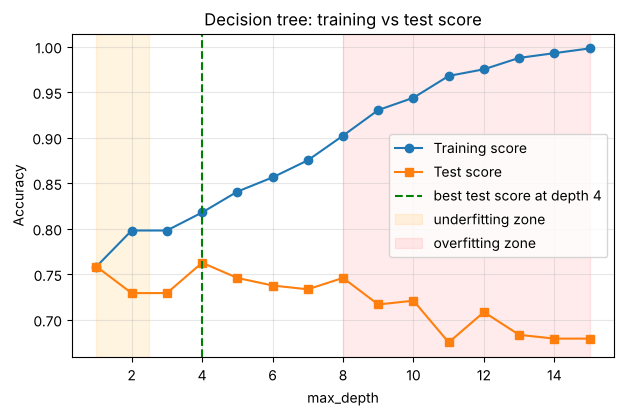

depth 1: train=0.758 test=0.758 | best depth 4: test=0.762 | depth 15: train=0.998 test=0.679


In [4]:
Xn_tr, Xn_te = X_train[num_cols], X_test[num_cols]
depths = range(1, 16); tr_s, te_s = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xn_tr, y_train)
    tr_s.append(t.score(Xn_tr, y_train)); te_s.append(t.score(Xn_te, y_test))
best_d = list(depths)[int(np.argmax(te_s))]

plt.figure(figsize=(7, 4.2))
plt.plot(depths, tr_s, "o-", label="Training score"); plt.plot(depths, te_s, "s-", label="Test score")
plt.axvline(best_d, color="g", ls="--", label=f"best test score at depth {best_d}")
plt.axvspan(1, 2.5, color="orange", alpha=.12, label="underfitting zone"); plt.axvspan(8, 15, color="red", alpha=.08, label="overfitting zone")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.title("Decision tree: training vs test score"); plt.legend(); plt.grid(alpha=.3); plt.show()
print(f"depth 1: train={tr_s[0]:.3f} test={te_s[0]:.3f} | best depth {best_d}: test={max(te_s):.3f} | depth 15: train={tr_s[-1]:.3f} test={te_s[-1]:.3f}")
R["q6"] = {"best_depth": best_d, "best_test": round(max(te_s), 4), "depth15_train": round(tr_s[-1], 4), "depth15_test": round(te_s[-1], 4), "depth1_train": round(tr_s[0], 4), "depth1_test": round(te_s[0], 4)}

- **Underfitting** (depth 1–2): both scores are low — the model is too simple to capture the pattern (high *bias*).
- **Overfitting** (deep trees): training ≈ 100 % but test is clearly lower — the model learned noise (high *variance*). The widening gap is the warning sign.

## Q7 (Medium) — `ColumnTransformer`: scale numeric + one-hot encode categorical in one step
Models only understand numbers, and distance/gradient-based models need features on a similar scale. `ColumnTransformer` applies a different transformer to each group of columns.

In [5]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])

Xt_train = preprocess.fit_transform(X_train)      # fit on TRAIN only
Xt_test  = preprocess.transform(X_test)           # reuse the learned statistics
names = preprocess.get_feature_names_out()
print("Before:", X_train.shape, "-> After:", Xt_train.shape)
print("Output columns:", list(names))
print("\nNumeric columns now ~ mean 0, std 1:")
print(pd.DataFrame(Xt_train[:, :5], columns=num_cols).agg(["mean", "std"]).round(3))
R["q7"] = {"before": list(X_train.shape), "after": list(Xt_train.shape)}

Before: (960, 9) -> After: (960, 15)
Output columns: ['num__study_hours', 'num__attendance', 'num__prev_gpa', 'num__sleep_hours', 'num__age', 'cat__parent_edu_bachelor', 'cat__parent_edu_high_school', 'cat__parent_edu_master', 'cat__parent_edu_phd', 'cat__internet_no', 'cat__internet_yes', 'cat__tutoring_no', 'cat__tutoring_yes', 'cat__school_type_private', 'cat__school_type_public']

Numeric columns now ~ mean 0, std 1:
      study_hours  attendance  prev_gpa  sleep_hours    age
mean        0.000       0.000    -0.000       -0.000 -0.000
std         1.001       1.001     1.001        1.001  1.001


**Why fit on train only?** The scaler's mean/std and the encoder's categories must come from training data alone; otherwise information from the test set leaks in (more on this on Day 4).

## Q8 (Medium) — Tune an SVM: `GridSearchCV` vs `RandomizedSearchCV`
* **Grid search** tries *every* combination in a fixed grid — thorough but expensive.
* **Randomized search** samples a fixed number of combinations from distributions — often finds an equally good model much faster, and can search continuous ranges.

In [6]:
svm_pipe = Pipeline([("prep", preprocess), ("svc", SVC(random_state=RANDOM_STATE))])
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

grid = GridSearchCV(svm_pipe, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.001, 0.01, 0.1], "svc__kernel": ["rbf", "linear"]},
                    cv=cv, scoring="accuracy", n_jobs=-1)
t0 = time.time(); grid.fit(X_train, y_train); t_grid = time.time() - t0

rand = RandomizedSearchCV(svm_pipe, {"svc__C": loguniform(1e-2, 1e3), "svc__gamma": loguniform(1e-4, 1e0), "svc__kernel": ["rbf", "linear"]},
                          n_iter=15, cv=cv, scoring="accuracy", random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time(); rand.fit(X_train, y_train); t_rand = time.time() - t0

cmp = pd.DataFrame({
    "combinations tried": [len(grid.cv_results_["params"]), len(rand.cv_results_["params"])],
    "best CV accuracy": [grid.best_score_, rand.best_score_],
    "test accuracy": [grid.score(X_test, y_test), rand.score(X_test, y_test)],
    "run time (s)": [t_grid, t_rand]}, index=["GridSearchCV", "RandomizedSearchCV"]).round(4)
print(cmp); print("\nBest params (grid):  ", grid.best_params_); print("Best params (random):", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rand.best_params_.items()})
R["q8"] = cmp.to_dict("index"); R["q8_params"] = {"grid": {k: str(v) for k, v in grid.best_params_.items()}}

                    combinations tried  best CV accuracy  test accuracy  \
GridSearchCV                        32            0.8208         0.8125   
RandomizedSearchCV                  15            0.8240         0.8167   

                    run time (s)  
GridSearchCV              6.5094  
RandomizedSearchCV        9.5342  

Best params (grid):   {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best params (random): {'svc__C': np.float64(0.0826), 'svc__gamma': np.float64(0.0016), 'svc__kernel': 'linear'}


Both searches land on almost the same score (the differences are within CV noise). Randomized search tried fewer candidates (15 vs 32), but on this small dataset the run times are similar: the cost is dominated by a few slow settings (e.g. a linear kernel with a large `C`) and by parallel start-up time, so the wall-clock gap is not a fair test.
The real difference is how they **scale**: grid search cost multiplies with every extra parameter value (`4 × 4 × 2 × 5 folds`), whereas randomized search cost is fixed by `n_iter` and it can sample continuous ranges (`loguniform`). On bigger grids or slower models, randomized search is the practical choice.

---
# Module A practical task — compare multiple models and justify the best
**Plan:** same preprocessing for every model (via a `Pipeline`, so no leakage), **5-fold CV on the training set** to compare, then **one** final evaluation of the winner on the untouched test set.
Metrics: accuracy, F1 and ROC-AUC (the target is mildly imbalanced, so accuracy alone is not enough). We also record the **train–CV gap** to see over/underfitting.

In [7]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN (k=7)":           KNeighborsClassifier(7),
    "Decision Tree (d=4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Naive Bayes":         GaussianNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (tuned, random)": None}      # filled in with the best estimator from Q8

rows = {}
for name, est in candidates.items():
    pipe = rand.best_estimator_ if est is None else Pipeline([("prep", preprocess), ("clf", est)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"], return_train_score=True, n_jobs=-1)
    rows[name] = {"CV accuracy": r["test_accuracy"].mean(), "CV F1": r["test_f1"].mean(), "CV ROC-AUC": r["test_roc_auc"].mean(),
                  "CV std (acc)": r["test_accuracy"].std(), "train acc": r["train_accuracy"].mean(),
                  "train–CV gap": r["train_accuracy"].mean() - r["test_accuracy"].mean()}
results = pd.DataFrame(rows).T.sort_values("CV F1", ascending=False).round(4)
results

,CV accuracy,CV F1,CV ROC-AUC,CV std (acc),train acc,train–CV gap
"SVM (tuned, random)",0.8240,0.8901,0.8367,0.0152,0.8289,0.0049
Logistic Regression,0.8208,0.8870,0.8369,0.0261,0.8310,0.0102
Random Forest,0.8010,0.8778,0.7978,0.0039,1.0000,0.1990
Gradient Boosting,0.8021,0.8753,0.8057,0.0189,0.9219,0.1198
KNN (k=7),0.7969,0.8747,0.7645,0.0208,0.8341,0.0372
Decision Tree (d=4),0.7812,0.8626,0.7653,0.0216,0.8279,0.0466
Naive Bayes,0.7740,0.8532,0.7660,0.0303,0.7826,0.0086


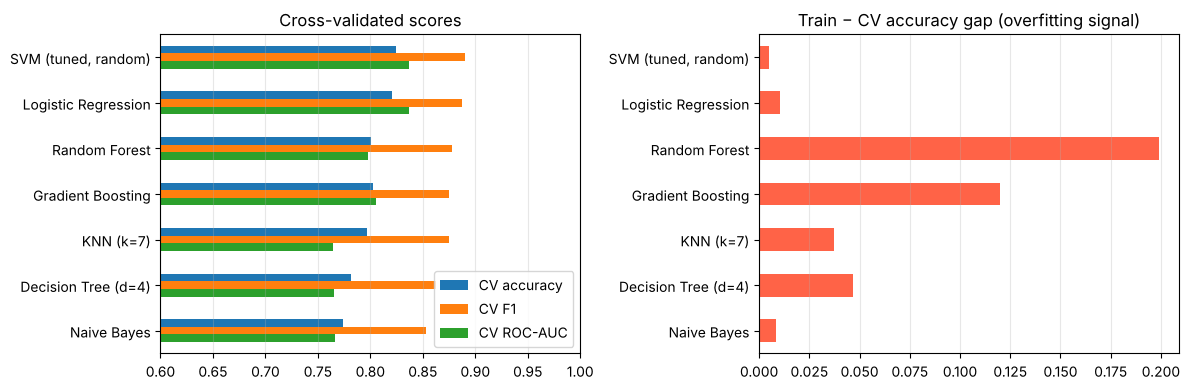

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
results[["CV accuracy", "CV F1", "CV ROC-AUC"]].plot.barh(ax=ax[0]); ax[0].set_xlim(.6, 1); ax[0].invert_yaxis(); ax[0].set_title("Cross-validated scores"); ax[0].grid(axis="x", alpha=.3)
results["train–CV gap"].plot.barh(ax=ax[1], color="tomato"); ax[1].invert_yaxis(); ax[1].set_title("Train − CV accuracy gap (overfitting signal)"); ax[1].grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

Winner by CV F1: SVM (tuned, random)
Final TEST scores (used once):  {'accuracy': 0.8167, 'f1': 0.8848, 'roc_auc': 0.8385}
              precision    recall  f1-score   support

        Fail       0.68      0.47      0.55        58
        Pass       0.84      0.93      0.88       182

    accuracy                           0.82       240
   macro avg       0.76      0.70      0.72       240
weighted avg       0.80      0.82      0.80       240



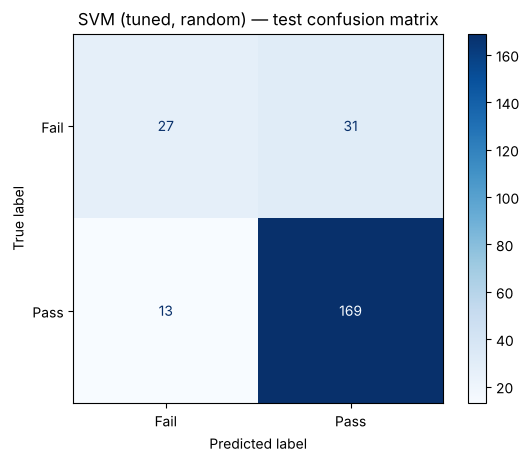


=== JUSTIFICATION ===
1. SVM (tuned, random) has the highest cross-validated F1 (0.890) and ROC-AUC 0.837.
2. Its train–CV gap is 0.005 -> small, so it generalises well.
3. Std across folds is 0.015, so the result is stable, not a lucky split.
4. Runner-ups: Logistic Regression (F1 0.887), Random Forest (F1 0.878) — differences among the top models are small, so a simpler/faster one is also a fair choice.
5. The test set was touched only once, after the model was chosen.


In [9]:
best_name = results.index[0]
best_pipe = rand.best_estimator_ if best_name.startswith("SVM") else Pipeline([("prep", preprocess), ("clf", candidates[best_name])])
best_pipe.fit(X_train, y_train)
pred = best_pipe.predict(X_test); proba = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe, "predict_proba") else best_pipe.decision_function(X_test)
test = {"accuracy": accuracy_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)}
print(f"Winner by CV F1: {best_name}\nFinal TEST scores (used once): ", {k: round(v, 4) for k, v in test.items()})
print(classification_report(y_test, pred, target_names=["Fail", "Pass"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Fail", "Pass"], cmap="Blues"); plt.title(f"{best_name} — test confusion matrix"); plt.show()

top3 = results.head(3)
print("\n=== JUSTIFICATION ===")
print(f"1. {best_name} has the highest cross-validated F1 ({results.loc[best_name,'CV F1']:.3f}) and ROC-AUC {results.loc[best_name,'CV ROC-AUC']:.3f}.")
print(f"2. Its train–CV gap is {results.loc[best_name,'train–CV gap']:.3f} -> " + ("small, so it generalises well." if results.loc[best_name,'train–CV gap'] < .05 else "noticeable, so some overfitting is present."))
print(f"3. Std across folds is {results.loc[best_name,'CV std (acc)']:.3f}, so the result is stable, not a lucky split.")
print(f"4. Runner-ups: " + ", ".join(f"{n} (F1 {v:.3f})" for n, v in top3['CV F1'].iloc[1:].items()) + " — differences among the top models are small, so a simpler/faster one is also a fair choice.")
print("5. The test set was touched only once, after the model was chosen.")
R["task"] = {"winner": best_name, "test": {k: round(v, 4) for k, v in test.items()}, "table": results[["CV accuracy", "CV F1", "CV ROC-AUC", "train–CV gap"]].to_dict("index")}

### Justification (how I decide)
1. **Choose on cross-validation, not on the test set** — the test set is only a final, honest check.
2. **Look beyond one number:** F1 and ROC-AUC alongside accuracy, because Pass/Fail is not perfectly balanced.
3. **Check the train–CV gap:** a large gap = overfitting (e.g. unpruned trees/forests memorise training data); both scores low = underfitting.
4. **When the top models are within noise of each other,** prefer the simpler, faster and more explainable one (e.g. logistic regression), because it is easier to maintain and explain to a stakeholder.

## Learning topic — Bias–variance trade-off
* **Bias** = error from a model that is too simple (it misses real patterns → *underfitting*).
* **Variance** = error from a model that is too sensitive to the training sample (it learns noise → *overfitting*).
* Making a model more complex (deeper trees, higher-degree polynomials, smaller `k` in KNN, larger `C`/`gamma` in SVM) **lowers bias but raises variance**. The goal is the sweet spot where *test* error is lowest — exactly what the depth curve in Q6 shows.
* Fixes: for high variance → more data, regularisation, pruning, simpler model, cross-validation, ensembles; for high bias → more features, a more flexible model, less regularisation.

### Summary of Day 2
| Concept | What I learned |
|---|---|
| Over/underfitting | Compare train vs test score as complexity grows |
| ColumnTransformer | One object to scale numeric + encode categorical, fit on train only |
| Grid vs Random search | Random search explores wide ranges faster at a similar score |
| Model comparison | Pipeline + CV + final single test evaluation + written justification |

In [10]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
